# **Proyecto Final:** SwingVision ⛳📷

## 0. Preparación

In [1]:
import cv2
import os
import glob
import copy
import numpy as np
import matplotlib.pyplot as plt

import config
from utils import load_images, write_image, show_images
from calibration import find_corners, calibrate_camera, compute_scale, save_calibration, load_calibration, undistort, prepare_frame, get_scale

output_folder = os.path.join(config.RESULTS_PATH, "calibration")
os.makedirs(output_folder, exist_ok=True)

## **Apartado A: Calibración de cámara**

La calibración se hace *offline*, antes de ejecutar el sistema, con los mismos pasos que en la Práctica 2. El resultado se guarda en ``results/calibration/calibration.npz`` y el resto del proyecto solo lo carga.

1. **Tarea A.1.** Cargar las imágenes del patrón con ``load_images()``.
2. **Tarea A.2.** Detectar y refinar las esquinas con ``cv2.findChessboardCorners()`` y ``cv2.cornerSubPix()``.
3. **Tarea A.3.** Calibrar con ``cv2.calibrateCamera()``.
4. **Tarea A.4.** Corregir la distorsión de una imagen.
5. **Tarea A.5.** Medir la escala (mm por píxel) con el tablero en el plano del jugador.
6. **Tarea A.6.** Guardar la calibración.

**Importante:** las imágenes del tablero tienen que estar grabadas en el mismo modo de vídeo que los swings (misma resolución y mismo objetivo). Para sacarlas de un vídeo se puede usar ``utils.extract_frames()``.

### **Tarea A.1:** Cargar las imágenes del patrón

In [2]:
imgs_path = sorted(glob.glob(os.path.join(config.DATA_PATH, "calibration", "calib_*.jpg")))
imgs = load_images(imgs_path)

print(f"{len(imgs)} images loaded")
print("Image shape:", imgs[0].shape)

15 images loaded
Image shape: (720, 1280, 3)


### **Tarea A.2:** Detectar y refinar las esquinas

In [3]:
corners = find_corners(imgs, config.PATTERN_SIZE)

print("Successful detections:", sum(cor[0] for cor in corners), "of", len(corners))
print("Failed:", [os.path.basename(p) for p, cor in zip(imgs_path, corners) if not cor[0]])

Successful detections: 15 of 15
Failed: []


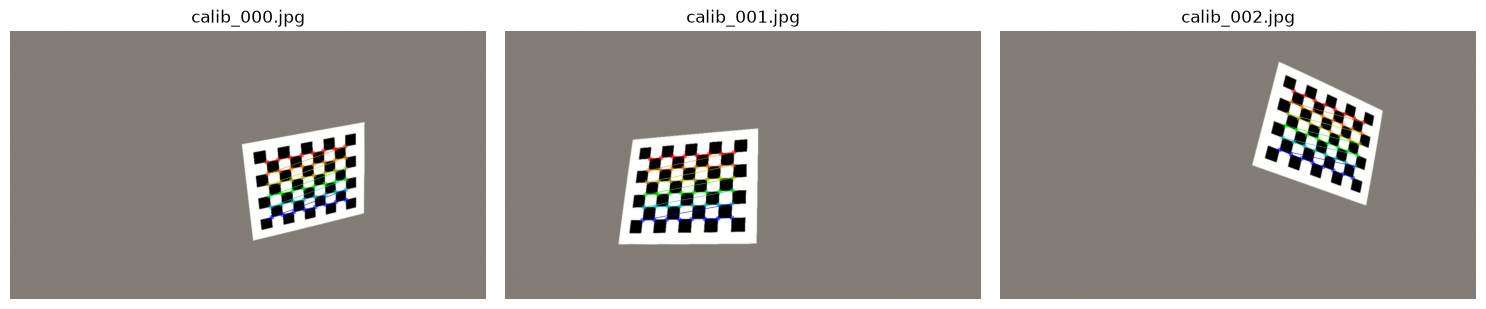

In [4]:
# Check the detections drawing them
imgs_copy = copy.deepcopy(imgs)
imgs_copy = [cv2.drawChessboardCorners(img, config.PATTERN_SIZE, cor[1], cor[0]) if cor[0] else img
             for img, cor in zip(imgs_copy, corners)]

for i in range(len(imgs)):
    write_image(output_folder, f"corners_{i:03d}.png", imgs_copy[i])
show_images(imgs_copy[:3], [os.path.basename(p) for p in imgs_path[:3]])

### **Tarea A.3:** Calibrar con ``cv2.calibrateCamera()``

In [5]:
rms, intrinsics, dist_coeffs, corners = calibrate_camera(imgs, config.PATTERN_SIZE, config.SQUARE_SIZE)

# Print outputs
np.set_printoptions(precision=4, suppress=True)
print("Intrinsics:\n", intrinsics)
print("Distortion coefficients:\n", dist_coeffs)
print("Root mean squared reprojection error:\n", rms)

Intrinsics:
 [[999.0075   0.     637.206 ]
 [  0.     998.7781 361.0669]
 [  0.       0.       1.    ]]
Distortion coefficients:
 [[-0.1215  0.0556  0.0004 -0.0005 -0.0384]]
Root mean squared reprojection error:
 0.20108385960744388


### **Tarea A.4:** Corregir la distorsión

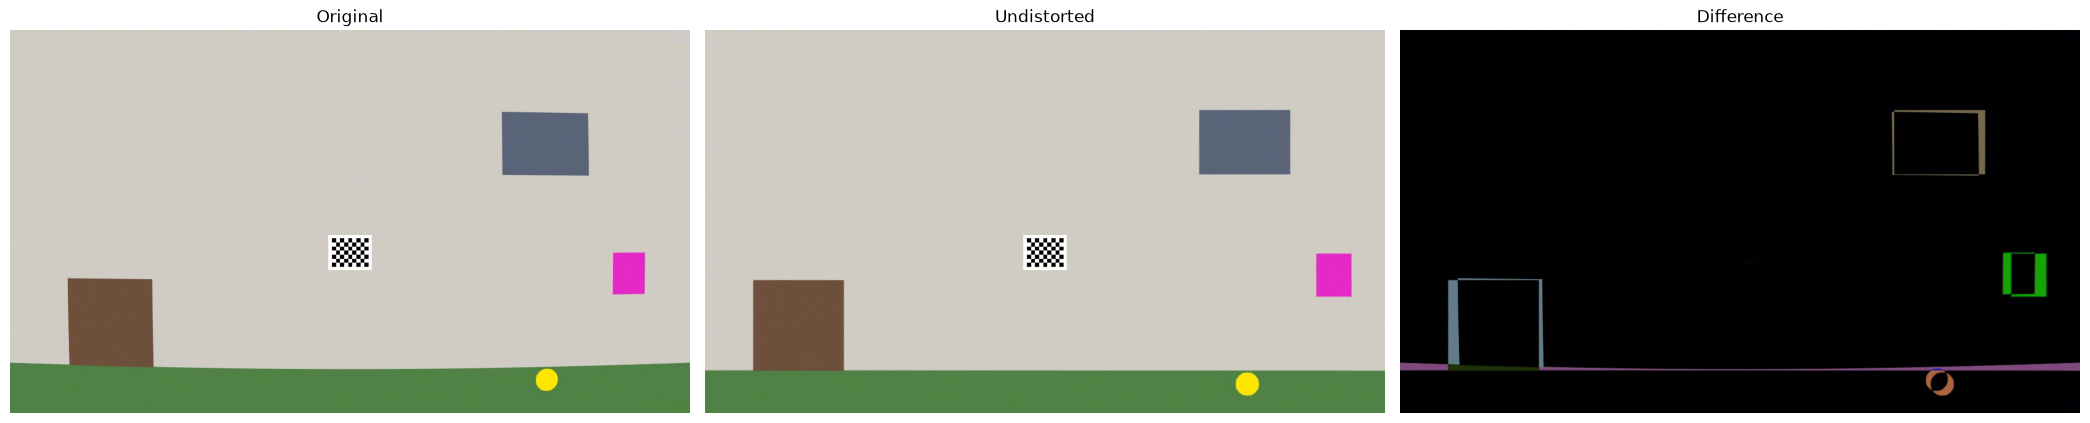

In [6]:
image_size = imgs[0].shape[1::-1]
calib = {"intrinsics": intrinsics, "dist_coeffs": dist_coeffs}

# Image of the scene: with distortion the straight lines (floor, edges of the board) are curved
scene = cv2.imread(os.path.join(config.DATA_PATH, "calibration", "scale.jpg"))
scene_undistorted = undistort(scene, calib)

write_image(output_folder, "A4_original.png", scene)
write_image(output_folder, "A4_corregida.png", scene_undistorted)
show_images([scene, scene_undistorted, cv2.absdiff(scene, scene_undistorted)], ["Original", "Undistorted", "Difference"], size=7)

### **Tarea A.5:** Escala en el plano del jugador

Con una sola cámara, un píxel solo equivale a una distancia fija en un plano concreto. Por eso el tablero se coloca **donde se pone el jugador, de frente a la cámara**: la separación entre esquinas (en píxeles) y el tamaño real del cuadrado (en mm) dan los milímetros por píxel en ese plano. Con esa escala se pasan a centímetros las diferencias de posición y a m/s las velocidades.

In [7]:
mm_per_px = compute_scale(scene_undistorted, config.PATTERN_SIZE, config.SQUARE_SIZE)
print("Scale in the plane of the player [mm/px]:", mm_per_px)
if mm_per_px is not None:
    print(f"Distance from the camera to that plane: {mm_per_px * intrinsics[0, 0] / 1000:.2f} m")

Scale in the plane of the player [mm/px]: 3.9550128055554
Distance from the camera to that plane: 3.95 m


### **Tarea A.6:** Guardar la calibración

In [8]:
save_calibration(config.CALIBRATION_FILE, rms, intrinsics, dist_coeffs, image_size, mm_per_px)

# Check: this is what the rest of the project does with every frame
calib = load_calibration()
frame = prepare_frame(scene, calib)
print("Prepared frame:", frame.shape, "- scale at that size [mm/px]:", get_scale(calib, frame.shape[1]))

Prepared frame: (540, 960, 3) - scale at that size [mm/px]: 5.273350407407199


#### **EXTRA A.3:** error de reproyección de cada imagen

``cv2.calibrateCamera()`` devuelve un único RMS. Para saber si alguna imagen estropea la calibración, proyectamos las esquinas del tablero con los parámetros obtenidos y medimos la distancia a las esquinas detectadas, imagen por imagen.

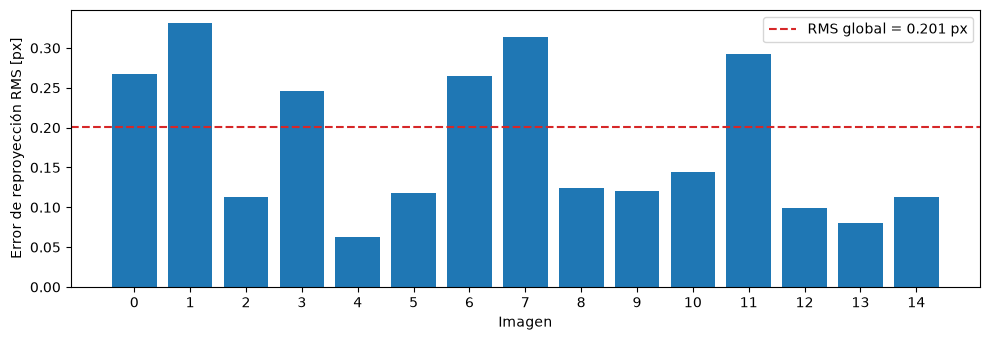

Worst image: 1 (0.331 px)


In [9]:
# EXTRA: reprojection error of every image
from utils import get_chessboard_points

valid_corners = np.array([cor[1] for cor in corners if cor[0]], dtype=np.float32)
chessboard_points = [get_chessboard_points(config.PATTERN_SIZE, config.SQUARE_SIZE, config.SQUARE_SIZE) for cor in corners if cor[0]]
_, K, dist, rvecs, tvecs = cv2.calibrateCamera(chessboard_points, valid_corners, image_size, None, None)

errors = []
for points, detected, rvec, tvec in zip(chessboard_points, valid_corners, rvecs, tvecs):
    projected, _ = cv2.projectPoints(points, rvec, tvec, K, dist)
    errors.append(np.sqrt(np.mean(np.sum((projected - detected) ** 2, axis=2))))

plt.figure(figsize=(10, 3.5))
plt.bar(range(len(errors)), errors, color="tab:blue")
plt.axhline(rms, color="tab:red", linestyle="--", label=f"RMS global = {rms:.3f} px")
plt.xlabel("Imagen")
plt.ylabel("Error de reproyección RMS [px]")
plt.xticks(range(len(errors)))
plt.legend()
plt.tight_layout()
plt.savefig(os.path.join(output_folder, "extra_error_por_imagen.png"), dpi=150)
plt.show()
print(f"Worst image: {np.argmax(errors)} ({max(errors):.3f} px)")